In [1]:
!pip install -q -U transformers datasets peft accelerate bitsandbytes gradio matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 119.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 48.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 57.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 130.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 19.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [1]:
# ===== Environment setup =====
import os, json, math, re
import torch, transformers, peft
from google.colab import drive, userdata
from huggingface_hub import login

drive.mount("/content/drive")

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU!")
print("transformers:", transformers.__version__, "| peft:", peft.__version__)

login(token=userdata.get("HF_TOKEN"))

# ===== Project configuration =====
PROJECT_DIR = "/content/drive/MyDrive/medical_assistant/v2"
os.makedirs(PROJECT_DIR, exist_ok=True)

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
MAX_LEN  = 768          # longer than v1 to fit questions + explanations
SEED     = 42
SYSTEM   = ("You are a careful, knowledgeable medical assistant. "
            "Answer accurately and concisely. You do not replace a doctor.")

print("Setup complete.")

Mounted at /content/drive
GPU: Tesla T4
transformers: 5.19.0 | peft: 0.21.2
Setup complete.


In [2]:
# ===== Load 4-bit quantized model =====
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.padding_side = "right"

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    dtype=torch.float16,
)
print(f"Model loaded. GPU memory: {torch.cuda.memory_allocated() / 1e9:.2f} GB / ~15 GB")
print("pad token:", tokenizer.pad_token, "| eos token:", tokenizer.eos_token)

# ===== Attach LoRA adapters =====
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)

peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
)
model = get_peft_model(model, peft_config)
model.print_trainable_parameters()

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded. GPU memory: 2.06 GB / ~15 GB
pad token: <|endoftext|> | eos token: <|im_end|>
trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


In [3]:
# ===== Helpers: inference and MedQA evaluation =====
from contextlib import nullcontext
from datasets import load_dataset

def adapter_ctx(use_adapter):
    """Disabling the LoRA adapter gives the original base model."""
    return nullcontext() if use_adapter else model.disable_adapter()

def ask(question, use_adapter=True, history=None, max_new_tokens=400):
    msgs = [{"role": "system", "content": SYSTEM}] + (history or []) + \
           [{"role": "user", "content": question}]
    text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    model.eval()
    with adapter_ctx(use_adapter), torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             repetition_penalty=1.1, pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)

LETTERS = ["A", "B", "C", "D"]
LETTER_IDS = [tokenizer.encode(l, add_special_tokens=False)[0] for l in LETTERS]

def format_mcq(question, options):
    """options: dict like {'A': '...', 'B': '...', 'C': '...', 'D': '...'}"""
    opts = "\n".join(f"{k}. {options[k]}" for k in LETTERS)
    return f"{question}\n\n{opts}\n\nAnswer with the letter of the correct option."

def medqa_preds(ds, use_adapter):
    """Returns a list of booleans: was each question answered correctly?"""
    results = []
    model.eval()
    with adapter_ctx(use_adapter), torch.no_grad():
        for ex in ds:
            msgs = [{"role": "system", "content": SYSTEM},
                    {"role": "user", "content": format_mcq(ex["question"], ex["options"])}]
            text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
            ids = tokenizer(text, return_tensors="pt").to(model.device)
            logits = model(**ids).logits[0, -1, LETTER_IDS]
            results.append(LETTERS[logits.argmax().item()] == ex["answer_idx"])
    return results

# ===== Baseline evaluation on the full MedQA test set =====
medqa_test = load_dataset("GBaker/MedQA-USMLE-4-options", split="test")
print("Letter token ids:", LETTER_IDS)
print("Test questions:", len(medqa_test))

base_preds = medqa_preds(medqa_test, use_adapter=False)
base_acc = sum(base_preds) / len(base_preds)
base_ci = 1.96 * math.sqrt(base_acc * (1 - base_acc) / len(base_preds))
print(f"\nBaseline Qwen2.5-3B-Instruct MedQA accuracy: {base_acc:.1%} (±{base_ci:.1%})")

json.dump({"base_acc": base_acc, "base_ci": base_ci, "base_preds": base_preds},
          open(f"{PROJECT_DIR}/baseline_medqa.json", "w"))
print("Saved baseline results to Drive.")

README.md:   0%|          | 0.00/654 [00:00<?, ?B/s]

phrases_no_exclude_train.jsonl: reconstructing file:   0%|          |  0.00B / 16.2MB            

phrases_no_exclude_train.jsonl: downloading bytes:           |  0.00B            

phrases_no_exclude_test.jsonl:   0%|          | 0.00/2.08M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/10178 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1273 [00:00<?, ? examples/s]

Letter token ids: [32, 33, 34, 35]
Test questions: 1273

Baseline Qwen2.5-3B-Instruct MedQA accuracy: 50.0% (±2.7%)
Saved baseline results to Drive.


In [4]:
# ===== Build the v2 training mixture =====
from datasets import concatenate_datasets
from collections import Counter

MCQ_LETTERS = ["A", "B", "C", "D"]

# --- 1. MedQA train (full) : USMLE-style questions, answer only ---
medqa_train = load_dataset("GBaker/MedQA-USMLE-4-options", split="train")
medqa_train = medqa_train.map(
    lambda x: {"question": format_mcq(x["question"], x["options"]),
               "answer": f"{x['answer_idx']}. {x['answer']}",
               "source": "medqa"},
    remove_columns=medqa_train.column_names)

# --- 2. MedMCQA : questions with expert explanations ---
ANS_PREFIX = re.compile(
    r"^\s*(ans(wer)?\.?\s*(is)?\s*[:\-]?\s*['\"(]?[a-d]['\")]?\s*[.,:]?\s*(i\.?\s?e\.?,?)?\s*)", re.I)
REF_SUFFIX = re.compile(r"\s*\(?\bref(erence)?s?\b\s*[:.\-].*$", re.I | re.S)

def clean_exp(text):
    text = ANS_PREFIX.sub("", text or "")
    text = REF_SUFFIX.sub("", text)
    return re.sub(r"\s+", " ", text).strip()

def medmcqa_ok(x):
    if x["choice_type"] != "single" or x["cop"] not in (0, 1, 2, 3):
        return False
    if not all((x[k] or "").strip() for k in ["opa", "opb", "opc", "opd"]):
        return False
    n_words = len(clean_exp(x["exp"]).split())
    return 20 <= n_words <= 250

def medmcqa_to_example(x):
    options = dict(zip(MCQ_LETTERS, [x["opa"], x["opb"], x["opc"], x["opd"]]))
    letter = MCQ_LETTERS[x["cop"]]
    return {"question": format_mcq(x["question"], options),
            "answer": f"{letter}. {options[letter]}\n\nExplanation: {clean_exp(x['exp'])}",
            "source": "medmcqa"}

medmcqa = load_dataset("openlifescienceai/medmcqa", split="train")
medmcqa = medmcqa.filter(medmcqa_ok).shuffle(seed=SEED).select(range(5000))
medmcqa = medmcqa.map(medmcqa_to_example, remove_columns=medmcqa.column_names)

# --- 3. WikiDoc : descriptive answers (same cleaning rules as v1) ---
BAD = re.compile(r"(found here|click here|see here|refer here|www\.|https?://)", re.I)
STOP = {"what", "does", "mean", "the", "are", "disease", "called", "information", "about",
        "can", "you", "provide", "overview", "with", "how", "which", "when", "there"}

def wikidoc_ok(x):
    q = (x["input"] or "").strip().strip('"')
    a = (x["output"] or "").strip()
    if not q or len(a.split()) < 20 or BAD.search(a):
        return False
    keys = [w for w in re.findall(r"[a-z0-9\-]{4,}", q.lower()) if w not in STOP]
    return any(k in a.lower() for k in keys)

wikidoc = load_dataset("medalpaca/medical_meadow_wikidoc", split="train")
wikidoc = wikidoc.filter(wikidoc_ok).shuffle(seed=SEED).select(range(1500))
wikidoc = wikidoc.map(
    lambda x: {"question": x["input"].strip().strip('"').strip(),
               "answer": re.sub(r"\s+", " ", x["output"]).strip(),
               "source": "wikidoc"},
    remove_columns=wikidoc.column_names)

# --- Combine, split, save ---
data = concatenate_datasets([medqa_train, medmcqa, wikidoc]).shuffle(seed=SEED)
split = data.train_test_split(test_size=300, seed=SEED)
split.save_to_disk(f"{PROJECT_DIR}/dataset")

print("Examples per source:", dict(Counter(data["source"])))
print(split)
for src in ["medqa", "medmcqa", "wikidoc"]:
    ex = next(e for e in split["train"] if e["source"] == src)
    print(f"\n========== {src} ==========")
    print("INPUT :", ex["question"][:500])
    print("OUTPUT:", ex["answer"][:500])

Map:   0%|          | 0/10178 [00:00<?, ? examples/s]

README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.9MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  936kB            

...

Filter:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/16378 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/300 [00:00<?, ? examples/s]

Examples per source: {'medqa': 10178, 'medmcqa': 5000, 'wikidoc': 1500}
DatasetDict({
    train: Dataset({
        features: ['question', 'answer', 'source'],
        num_rows: 16378
    })
    test: Dataset({
        features: ['question', 'answer', 'source'],
        num_rows: 300
    })
})

========== medqa ==========
INPUT : A 58-year-old department store manager comes to his doctor’s office complaining that he had recently been waking up in the middle of the night with abdominal pain. This has happened several nights a week in the past month. He has also been experiencing occasional discomfort in the afternoon. The patient's appetite has suffered as a result of the pain he was experiencing. His clothes hang on him loosely. The patient does not take any prescription or over the counter medications. The remainder of 
OUTPUT: A. In the pyloric channel within 3 cm of the pylorus

========== medmcqa ==========
INPUT : Which of the following is not an oppounistic infection in renal tran

In [5]:
# ===== Strict WikiDoc filter: keep only answers that match the question's intent =====
import random

INTENTS = [  # (question pattern, required answer pattern) - specific intents first
    (r"symptom|sign|present|history|complain",            r"symptom|sign|present|complain|history"),
    (r"diagnos|test|laborator|lab |imaging|x-ray|ct |mri|ecg|finding|biopsy",
                                                          r"diagnos|test|laborator|imaging|x-ray|ct|mri|ecg|finding|biopsy|level"),
    (r"treat|therap|manage|medication|drug|surgery|cure",  r"treat|therap|manage|medication|drug|surg|dose|administer"),
    (r"cause|etiolog|risk factor|why does|pathogen|pathophysiolog",
                                                          r"cause|etiolog|risk|due to|result|mutation|mechanism|pathogen"),
    (r"epidemiolog|prevalen|incidence|how common|demograph", r"prevalen|incidence|per 100|%|affect|common"),
]
DEFINITION_Q = r"what (is|are|does)|mean|definition|define|overview|describe|explain|tell me about"
DEFINITION_A = r"\b(is an?|are an?|is the|are the|refers? to|is defined|is characterized|is a type|is a form)\b"
NOT_DEFINITION = r"diagnos|treatment|history|imaging|laborator|prognosis|screening"

def first_sentences(text, n=2):
    return " ".join(re.split(r"(?<=[.!?])\s+", text)[:n]).lower()

def key_terms(q):
    return [w for w in re.findall(r"[a-z0-9\-]{4,}", q.lower()) if w not in STOP]

def wikidoc_strict_ok(x):
    q = (x["input"] or "").strip().strip('"').lower()
    a = (x["output"] or "").strip()
    if not q or len(a.split()) < 25 or len(a.split()) > 350 or BAD.search(a):
        return False
    head = first_sentences(a, 2)
    keys = key_terms(q)
    if not keys or not any(k in head for k in keys):          # topic must appear at the start
        return False
    for q_pat, a_pat in INTENTS:                              # specific intents
        if re.search(q_pat, q):
            return bool(re.search(a_pat, head))
    if re.search(DEFINITION_Q, q):                            # "what is X?" questions
        first = first_sentences(a, 1)
        return bool(re.search(DEFINITION_A, first)) and not re.search(NOT_DEFINITION, first)
    return False                                              # unknown intent -> drop

wiki_raw = load_dataset("medalpaca/medical_meadow_wikidoc", split="train")
wiki_ok = wiki_raw.filter(wikidoc_strict_ok)
print(f"WikiDoc kept by strict filter: {len(wiki_ok)} / {len(wiki_raw)}")

wiki_ok = wiki_ok.shuffle(seed=SEED).select(range(min(1500, len(wiki_ok))))
wiki_ok = wiki_ok.map(
    lambda x: {"question": x["input"].strip().strip('"').strip(),
               "answer": re.sub(r"\s+", " ", x["output"]).strip(),
               "source": "wikidoc"},
    remove_columns=wiki_ok.column_names)
wiki_split = wiki_ok.train_test_split(test_size=50, seed=SEED)

# Replace old WikiDoc rows with the strictly filtered ones
split["train"] = concatenate_datasets([split["train"].filter(lambda x: x["source"] != "wikidoc"),
                                       wiki_split["train"]]).shuffle(seed=SEED)
split["test"]  = concatenate_datasets([split["test"].filter(lambda x: x["source"] != "wikidoc"),
                                       wiki_split["test"]])
split.save_to_disk(f"{PROJECT_DIR}/dataset_final")

print("Train sources:", dict(Counter(split["train"]["source"])))
print("Eval sources :", dict(Counter(split["test"]["source"])))

# Manual review: 6 random WikiDoc samples
random.seed(0)
wiki_rows = [e for e in split["train"] if e["source"] == "wikidoc"]
for ex in random.sample(wiki_rows, 6):
    print("\nQ:", ex["question"])
    print("A:", ex["answer"][:300])

Filter:   0%|          | 0/10000 [00:00<?, ? examples/s]

WikiDoc kept by strict filter: 2165 / 10000


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Filter:   0%|          | 0/16378 [00:00<?, ? examples/s]

Filter:   0%|          | 0/300 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/16346 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/332 [00:00<?, ? examples/s]

Train sources: {'medqa': 10001, 'medmcqa': 4895, 'wikidoc': 1450}
Eval sources : {'medmcqa': 105, 'medqa': 177, 'wikidoc': 50}

Q: What role does MRI play in the diagnosis of neurofibroma?
A: MRI may be helpful in the diagnosis of neurofibroma MRI signal characteristics include: MRI sequence Characteristics T1 Hypointense Homogeneous low signal intensity Center demonstrating a higher signal intensity than the periphery (reverse of target sign on T2) T2 Hyperintense Homogeneous high signa

Q: What causes Tetralogy of Fallot?
A: Common causes of tetralogy of Fallot may include: Alcoholism in the mother Diabetes Pregnancy after the age of 40 Rubella or other viral illnesses during pregnancy Phenylketonuria (PKU) in the mother Fetal hydantoin syndrome Fetal carbamazepine syndrome Less common causes of tetralogy of Fallot may 

Q: What does the term Natural Orifice Translumenal Endoscopic Surgery (NOTES) mean?
A: Natural orifice transluminal surgery (NOTES) is a rapidly evolving field which

In [6]:
# ===== Remove WikiDoc questions corrupted by an automatic paraphrasing step =====
META = re.compile(
    r"rephras|paraphras|rewrit|reword|the (given|following|provided) (sentence|text)|"
    r"proper english|grammatical|exact sentence|provide me with|as an ai|language model|"
    r"i'm sorry|i apologize|please provide",
    re.I)

def not_meta(x):
    return x["source"] != "wikidoc" or not META.search(x["question"])

n_tr, n_te = len(split["train"]), len(split["test"])
split["train"] = split["train"].filter(not_meta)
split["test"]  = split["test"].filter(not_meta)
print(f"Removed corrupted questions -> train: {n_tr - len(split['train'])} | eval: {n_te - len(split['test'])}")

split.save_to_disk(f"{PROJECT_DIR}/dataset_final_v2")
print("Train sources:", dict(Counter(split["train"]["source"])))
print("Eval sources :", dict(Counter(split["test"]["source"])))

# Second manual review with a different random sample
random.seed(1)
wiki_rows = [e for e in split["train"] if e["source"] == "wikidoc"]
for ex in random.sample(wiki_rows, 6):
    print("\nQ:", ex["question"])
    print("A:", ex["answer"][:250])

Filter:   0%|          | 0/16346 [00:00<?, ? examples/s]

Filter:   0%|          | 0/332 [00:00<?, ? examples/s]

Removed corrupted questions -> train: 25 | eval: 1


Saving the dataset (0/1 shards):   0%|          | 0/16321 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/331 [00:00<?, ? examples/s]

Train sources: {'medqa': 10001, 'medmcqa': 4895, 'wikidoc': 1425}
Eval sources : {'medmcqa': 105, 'medqa': 177, 'wikidoc': 49}

Q: What laboratory tests are conducted for Ebola?
A: Several diagnostic tests are available for detection of Ebola virus disease (EVD). Acute infections are confirmed using a real-time RT- PCR assay. Virus isolation may also be attempted. Serologic testing for IgM and IgG antibodies is completed for ce

Q: What is the definition of mucositis and what treatments are currently available for it?
A: Treatment of mucositis is mainly supportive. Oral hygiene is the mainstay of treatment; patients are encouraged to clean their mouth every four hours and at bedtime, more often if the mucositis becomes worse. Water-soluble jellies can be used to lubr

Q: What role does the CT scan have in the diagnosis of Leiomyosarcoma?
A: The CT scan can be used to assess the metastasis to the lungs and mediastinum and also follow up after surgical removal or recurrence evaluation. T

In [3]:
# ===== Resume path: load the final cleaned dataset from Drive =====
from datasets import load_from_disk
from collections import Counter

split = load_from_disk(f"{PROJECT_DIR}/dataset_final_v2")
print(split)
print("Train sources:", dict(Counter(split["train"]["source"])))

DatasetDict({
    train: Dataset({
        features: ['question', 'answer', 'source'],
        num_rows: 16321
    })
    test: Dataset({
        features: ['question', 'answer', 'source'],
        num_rows: 331
    })
})
Train sources: {'medqa': 10001, 'medmcqa': 4895, 'wikidoc': 1425}


In [4]:
# ===== Tokenize with loss masking (loss only on the answer) =====
import numpy as np

def build_example(ex):
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": ex["question"]}]
    prompt = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    full = prompt + ex["answer"] + tokenizer.eos_token

    prompt_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    full_ids = tokenizer(full, add_special_tokens=False, truncation=True, max_length=MAX_LEN)["input_ids"]
    labels = ([-100] * len(prompt_ids) + full_ids[len(prompt_ids):])[:len(full_ids)]
    return {"input_ids": full_ids, "attention_mask": [1] * len(full_ids), "labels": labels}

cols = ["question", "answer", "source"]
train_ds = split["train"].map(build_example, remove_columns=cols)
eval_ds  = split["test"].map(build_example,  remove_columns=cols)

# Drop examples whose answer was fully truncated away
has_answer = lambda x: any(l != -100 for l in x["labels"])
n_before = len(train_ds)
train_ds = train_ds.filter(has_answer)
eval_ds  = eval_ds.filter(has_answer)

# ===== Sanity checks =====
ex = train_ds[0]
learned = [t for t, l in zip(ex["input_ids"], ex["labels"]) if l != -100]
print("Tokens the loss is computed on:\n", tokenizer.decode(learned))

lens = np.array([len(x) for x in train_ds["input_ids"]])
print(f"\nSequence length: mean {lens.mean():.0f} | median {np.median(lens):.0f} | max {lens.max()}")
print(f"Truncated (hit {MAX_LEN}): {(lens >= MAX_LEN).sum()} / {len(lens)} ({(lens >= MAX_LEN).mean():.1%})")
print(f"Removed (no answer left): {n_before - len(train_ds)}")
print(f"Final -> train: {len(train_ds)} | eval: {len(eval_ds)}")

Map:   0%|          | 0/16321 [00:00<?, ? examples/s]

Map:   0%|          | 0/331 [00:00<?, ? examples/s]

Filter:   0%|          | 0/16321 [00:00<?, ? examples/s]

Filter:   0%|          | 0/331 [00:00<?, ? examples/s]

Tokens the loss is computed on:
 B. Mutation of the JAK2 gene is commonly seen in this condition.<|im_end|>

Sequence length: mean 245 | median 232 | max 768
Truncated (hit 768): 1 / 16319 (0.0%)
Removed (no answer left): 2
Final -> train: 16319 | eval: 331


In [5]:
# ===== Training (resumable) =====
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq
from transformers.trainer_utils import get_last_checkpoint

CKPT_DIR = f"{PROJECT_DIR}/checkpoints"

args = TrainingArguments(
    output_dir=CKPT_DIR,
    num_train_epochs=1,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,      # effective batch size 16 -> ~1020 steps
    learning_rate=1e-4,                 # lower than v1: larger model, more data
    lr_scheduler_type="cosine",
    warmup_steps=30,
    optim="paged_adamw_8bit",
    fp16=True,
    max_grad_norm=0.3,
    logging_steps=25,
    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=eval_ds,
    data_collator=DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100),
)

last_ckpt = get_last_checkpoint(CKPT_DIR) if os.path.isdir(CKPT_DIR) else None
print("Resuming from:", last_ckpt if last_ckpt else "scratch")

model.config.use_cache = False
trainer.train(resume_from_checkpoint=last_ckpt)
model.config.use_cache = True

# Save the best adapter immediately
ADAPTER_DIR = f"{PROJECT_DIR}/qwen3b-medical-lora"
model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
print("Training finished. Best adapter saved to:", ADAPTER_DIR)

Resuming from: /content/drive/MyDrive/medical_assistant/v2/checkpoints/checkpoint-800


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss,Validation Loss
900,1.639203,1.492482
1000,1.730668,1.492220
1020,1.730668,1.492199


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Training finished. Best adapter saved to: /content/drive/MyDrive/medical_assistant/v2/qwen3b-medical-lora


In [6]:
# ===== Final evaluation: fine-tuned vs. base on the full MedQA test set =====
from contextlib import nullcontext
from datasets import load_dataset
from scipy.stats import binomtest

def adapter_ctx(use_adapter):
    return nullcontext() if use_adapter else model.disable_adapter()

LETTERS = ["A", "B", "C", "D"]
LETTER_IDS = [tokenizer.encode(l, add_special_tokens=False)[0] for l in LETTERS]

def format_mcq(question, options):
    opts = "\n".join(f"{k}. {options[k]}" for k in LETTERS)
    return f"{question}\n\n{opts}\n\nAnswer with the letter of the correct option."

def medqa_preds(ds, use_adapter):
    results = []
    model.eval()
    with adapter_ctx(use_adapter), torch.no_grad():
        for ex in ds:
            msgs = [{"role": "system", "content": SYSTEM},
                    {"role": "user", "content": format_mcq(ex["question"], ex["options"])}]
            text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
            ids = tokenizer(text, return_tensors="pt").to(model.device)
            logits = model(**ids).logits[0, -1, LETTER_IDS]
            results.append(LETTERS[logits.argmax().item()] == ex["answer_idx"])
    return results

# Baseline results saved before training
baseline = json.load(open(f"{PROJECT_DIR}/baseline_medqa.json"))
base_preds = baseline["base_preds"]

# Evaluate the fine-tuned model on the same 1273 questions
medqa_test = load_dataset("GBaker/MedQA-USMLE-4-options", split="test")
ft_preds = medqa_preds(medqa_test, use_adapter=True)

n = len(base_preds)
def acc_ci(r):
    p = sum(r) / n
    return p, 1.96 * math.sqrt(p * (1 - p) / n)

p_b, ci_b = acc_ci(base_preds)
p_a, ci_a = acc_ci(ft_preds)
only_base = sum(b and not a for b, a in zip(base_preds, ft_preds))
only_ft   = sum(a and not b for b, a in zip(base_preds, ft_preds))
p_value = binomtest(only_ft, only_base + only_ft, 0.5).pvalue

print("=" * 62)
print(f"MedQA (USMLE, 4 options) - {n} test questions")
print("=" * 62)
print(f"Qwen2.5-3B-Instruct (base) : {p_b:.1%}  (±{ci_b:.1%})")
print(f"Qwen2.5-3B + QLoRA (ours)  : {p_a:.1%}  (±{ci_a:.1%})")
print(f"Absolute change            : {(p_a - p_b) * 100:+.1f} points")
print("-" * 62)
print(f"Correct only by base model : {only_base}")
print(f"Correct only by fine-tuned : {only_ft}")
print(f"McNemar exact p-value      : {p_value:.2e}")
print("Statistically significant (p < 0.05)" if p_value < 0.05 and p_a > p_b
      else "NOT statistically significant")

json.dump({"n": n, "acc_base": p_b, "acc_finetuned": p_a, "ci_base": ci_b, "ci_finetuned": ci_a,
           "only_base": only_base, "only_finetuned": only_ft, "p_value": p_value,
           "finetuned_preds": ft_preds},
          open(f"{PROJECT_DIR}/final_medqa_results.json", "w"), indent=2)
print("\nResults saved to Drive.")

README.md:   0%|          | 0.00/654 [00:00<?, ?B/s]

phrases_no_exclude_train.jsonl: reconstructing file:   0%|          |  0.00B / 16.2MB            

phrases_no_exclude_train.jsonl: downloading bytes:           |  0.00B            

phrases_no_exclude_test.jsonl:   0%|          | 0.00/2.08M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/10178 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1273 [00:00<?, ? examples/s]

MedQA (USMLE, 4 options) - 1273 test questions
Qwen2.5-3B-Instruct (base) : 50.0%  (±2.7%)
Qwen2.5-3B + QLoRA (ours)  : 52.6%  (±2.7%)
Absolute change            : +2.5 points
--------------------------------------------------------------
Correct only by base model : 102
Correct only by fine-tuned : 134
McNemar exact p-value      : 4.34e-02
Statistically significant (p < 0.05)

Results saved to Drive.


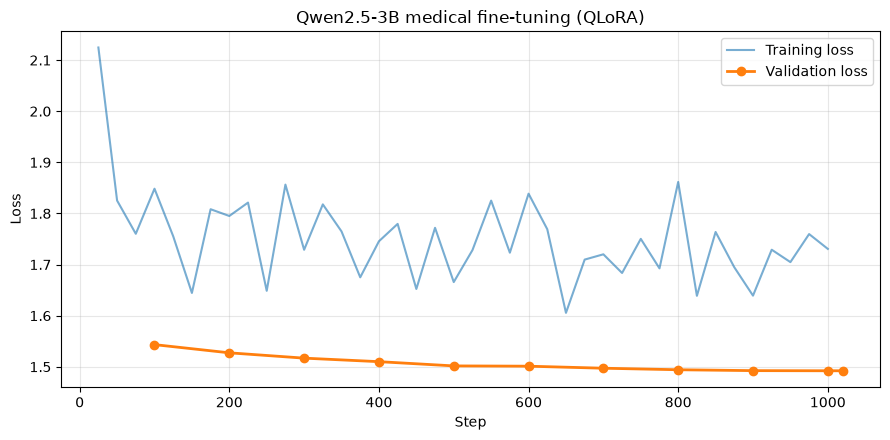

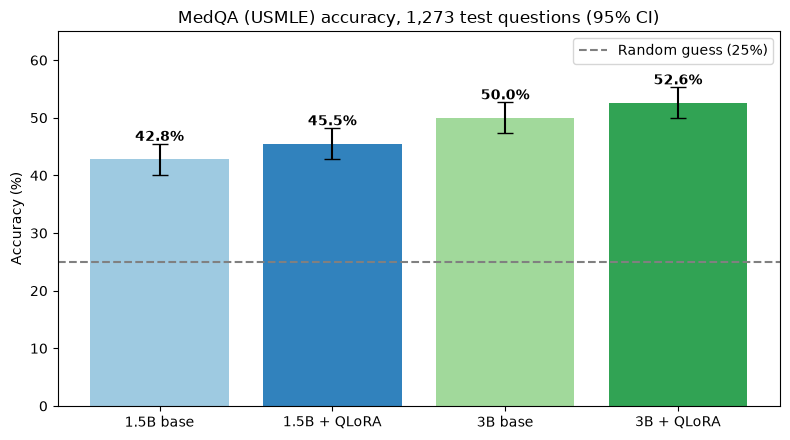

Figures saved to: /content/drive/MyDrive/medical_assistant/v2/figures


In [7]:
# ===== Figures for the README =====
import matplotlib.pyplot as plt

FIG_DIR = f"{PROJECT_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# --- 1. Full loss curve (history restored from checkpoints + resumed run) ---
logs = trainer.state.log_history
tr = sorted({l["step"]: l["loss"] for l in logs if "loss" in l}.items())
ev = sorted({l["step"]: l["eval_loss"] for l in logs if "eval_loss" in l}.items())

plt.figure(figsize=(9, 4.5))
plt.plot(*zip(*tr), alpha=0.6, label="Training loss")
plt.plot(*zip(*ev), "o-", linewidth=2, label="Validation loss")
plt.xlabel("Step"); plt.ylabel("Loss")
plt.title("Qwen2.5-3B medical fine-tuning (QLoRA)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/loss_curve.png", dpi=150); plt.show()

# --- 2. MedQA results ---
names = ["1.5B base", "1.5B + QLoRA", "3B base", "3B + QLoRA"]
accs  = [42.8, 45.5, 50.0, 52.6]
colors = ["#9ecae1", "#3182bd", "#a1d99b", "#31a354"]

plt.figure(figsize=(8, 4.5))
bars = plt.bar(names, accs, yerr=2.7, capsize=6, color=colors)
for b, a in zip(bars, accs):
    plt.text(b.get_x() + b.get_width() / 2, a + 3.2, f"{a:.1f}%", ha="center", fontweight="bold")
plt.axhline(25, ls="--", color="gray", label="Random guess (25%)")
plt.ylabel("Accuracy (%)"); plt.ylim(0, 65)
plt.title("MedQA (USMLE) accuracy, 1,273 test questions (95% CI)")
plt.legend(); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/medqa_results.png", dpi=150); plt.show()

print("Figures saved to:", FIG_DIR)